# Notebook 01 — Data Loading & First Look
**Project:** Predicting Employee Attrition at PeopleFirst Global Services  
**Dataset:** PeopleFirst_Workforce_Intelligence.csv  
**Step:** Month 1, Weeks 1–2 — Data Collection & Integration  

---

### Objectives of this notebook
1. Load the dataset and confirm it loaded correctly
2. Understand the shape, columns, and data types
3. Identify the target variable and check class distribution
4. Spot missing values, data quality issues, and legacy/ID columns
5. Save a clean summary for reference in later notebooks


## 

## 1. Import Libraries

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)

print("Libraries loaded successfully.")


Libraries loaded successfully.


## 2. Load the Dataset

In [12]:

DATA_PATH = '../data/raw/PeopleFirst_Workforce_Intelligence.csv'

df = pd.read_csv(DATA_PATH)

print(f"Dataset loaded successfully.")
print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]}")


Dataset loaded successfully.
Rows    : 50,500
Columns : 36


In [13]:

df.head()


,employee_id,age,gender,marital_status,education_level,department,job_role,years_at_company,years_in_current_role,promotion_last_5y,...,manager_relationship_score,work_life_balance_score,engagement_score,recruitment_source,employment_type,legacy_hr_record,employee_cluster_id,survey_batch_id,payroll_reference_number,attrition_flag
0,100000,59,Female,Single,Diploma,Sales,Analyst,16,9,0,...,9.193530,7.646637,7.363357,Campus,Intern,880246,59,7571,868037,1
1,100001,49,Male,Single,PhD,HR,Manager,17,5,0,...,6.690203,7.778092,NaN,Referral,Intern,487936,61,5161,579256,0
2,100002,35,Female,Single,Bachelors,Operations,Administrator,9,9,0,...,2.668998,8.827286,1.396038,Job Portal,Permanent,262254,26,8009,172606,1
3,100003,28,Male,Divorced,Masters,HR,Manager,6,8,0,...,5.721819,1.864961,3.701012,Agency,Contract,191081,73,9727,916451,1
4,100004,41,Female,Single,PhD,Technology,Director,10,7,0,...,5.666429,7.880418,6.476967,Campus,Intern,477952,64,6152,635476,1


In [14]:

df.tail()


,employee_id,age,gender,marital_status,education_level,department,job_role,years_at_company,years_in_current_role,promotion_last_5y,...,manager_relationship_score,work_life_balance_score,engagement_score,recruitment_source,employment_type,legacy_hr_record,employee_cluster_id,survey_batch_id,payroll_reference_number,attrition_flag
50495,100314,53,Female,Married,Masters,Marketing,Administrator,4,8,0,...,1.753468,6.168695,9.335085,Campus,Permanent,749082,85,4596,380969,0
50496,111449,23,Female,Single,Diploma,Marketing,Manager,11,9,0,...,5.512475,1.683026,3.883434,Referral,Permanent,472038,14,3924,713672,1
50497,130745,29,Female,Single,Bachelors,Technology,Manager,10,2,0,...,1.335195,7.052158,NaN,Job Portal,Intern,290410,37,9038,183569,1
50498,129702,58,Male,Divorced,Masters,Operations,Director,5,6,0,...,2.814989,8.127648,1.326804,Internal,Intern,470605,29,3385,886856,1
50499,127658,44,Female,Divorced,Bachelors,Sales,Manager,10,1,1,...,7.246067,1.930223,7.062654,Referral,Intern,772101,42,3817,945429,0


## 3. Column Overview

In [15]:

df.dtypes


employee_id                        int64
age                                int64
gender                               str
marital_status                       str
education_level                      str
department                           str
job_role                             str
years_at_company                   int64
years_in_current_role              int64
promotion_last_5y                  int64
monthly_salary                   float64
annual_bonus                     float64
salary_hike_pct                  float64
performance_rating               float64
manager_rating                   float64
goal_achievement_pct             float64
avg_monthly_overtime_hours       float64
avg_weekly_work_hours            float64
remote_work_days_per_month         int64
business_travel_frequency            str
absenteeism_days_last_12m          int64
late_arrivals_last_12m             int64
training_hours_last_12m          float64
certifications_completed           int64
learning_platfor

In [16]:

ID_COLS = [
    'employee_id',
    'legacy_hr_record',        # Legacy field — no analytical value
    'employee_cluster_id',     # Legacy field — no analytical value
    'survey_batch_id',         # Administrative reference
    'payroll_reference_number' # Administrative reference
]

DEMOGRAPHIC_COLS = ['age', 'gender', 'marital_status', 'education_level']

JOB_COLS = [
    'department', 'job_role', 'employment_type',
    'years_at_company', 'years_in_current_role', 'promotion_last_5y',
    'recruitment_source', 'business_travel_frequency'
]

COMPENSATION_COLS = ['monthly_salary', 'annual_bonus', 'salary_hike_pct']

PERFORMANCE_COLS = [
    'performance_rating', 'manager_rating',
    'goal_achievement_pct'
]

WORKLOAD_COLS = [
    'avg_monthly_overtime_hours', 'avg_weekly_work_hours',
    'remote_work_days_per_month', 'absenteeism_days_last_12m',
    'late_arrivals_last_12m'
]

LEARNING_COLS = [
    'training_hours_last_12m', 'certifications_completed',
    'learning_platform_usage_hours'
]

ENGAGEMENT_COLS = [
    'employee_satisfaction_score', 'manager_relationship_score',
    'work_life_balance_score', 'engagement_score'
]

TARGET_COL = 'attrition_flag'

print("Column groups defined.")
print(f"Total feature columns accounted for: {len(ID_COLS + DEMOGRAPHIC_COLS + JOB_COLS + COMPENSATION_COLS + PERFORMANCE_COLS + WORKLOAD_COLS + LEARNING_COLS + ENGAGEMENT_COLS)}")
print(f"+ Target: {TARGET_COL}")


Column groups defined.
Total feature columns accounted for: 35
+ Target: attrition_flag


## 4. Target Variable — Attrition Flag
`attrition_flag` = 1 means the employee left (attrition), 0 means they stayed.

> **Note:** The attrition rate in this dataset is ~61% — much higher than a typical corporate dataset (~15–20%).  
> This means the **majority class is "left" (1)**, and the minority class is "stayed" (0).  
> This is the **opposite** of what SMOTE usually handles — we will address this in Notebook 04  
> by either oversampling the minority class (stayed) or using class weighting.


In [17]:
# Class distribution
target_counts = df[TARGET_COL].value_counts()
target_pct    = df[TARGET_COL].value_counts(normalize=True) * 100

print("=== Target Variable Distribution ===")
print(f"Stayed (0) : {target_counts[0]:,}  ({target_pct[0]:.2f}%)")
print(f"Left   (1) : {target_counts[1]:,}  ({target_pct[1]:.2f}%)")
print(f"\nAttrition rate : {target_pct[1]:.2f}%")
print(f"Class imbalance ratio (left:stayed) : {target_counts[1]/target_counts[0]:.2f}:1")


=== Target Variable Distribution ===
Stayed (0) : 19,471  (38.56%)
Left   (1) : 31,029  (61.44%)

Attrition rate : 61.44%
Class imbalance ratio (left:stayed) : 1.59:1


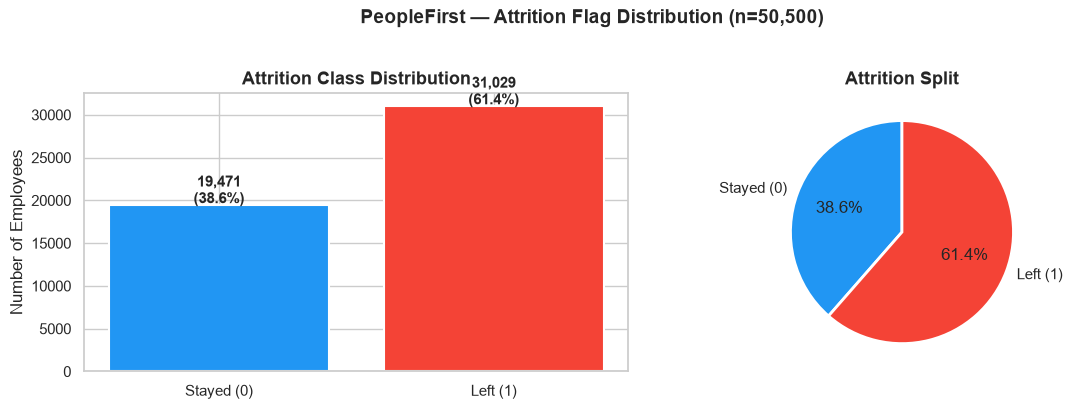

Chart saved to reports/


In [18]:
# Visualise class distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart
axes[0].bar(['Stayed (0)', 'Left (1)'],
            [target_counts[0], target_counts[1]],
            color=['#2196F3', '#F44336'], edgecolor='white', linewidth=1.5)
axes[0].set_title('Attrition Class Distribution', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Number of Employees')
for i, v in enumerate([target_counts[0], target_counts[1]]):
    axes[0].text(i, v + 200, f'{v:,}\n({v/len(df)*100:.1f}%)',
                 ha='center', fontsize=11, fontweight='bold')

# Pie chart
axes[1].pie([target_counts[0], target_counts[1]],
            labels=['Stayed (0)', 'Left (1)'],
            autopct='%1.1f%%',
            colors=['#2196F3', '#F44336'],
            startangle=90, wedgeprops=dict(edgecolor='white', linewidth=2))
axes[1].set_title('Attrition Split', fontsize=13, fontweight='bold')

plt.suptitle('PeopleFirst — Attrition Flag Distribution (n=50,500)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../reports/01_target_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved to reports/")


## 5. Missing Values
Only 2 columns have missing values — both are from the engagement survey system,  
which suggests the gap is a **survey non-response / system extraction issue**, not random.  
We will handle imputation in Notebook 02 (Cleaning).


In [19]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing Count', ascending=False)

print("=== Columns with Missing Values ===")
print(missing_df.to_string())


=== Columns with Missing Values ===
                  Missing Count  Missing %
manager_rating             5033       9.97
engagement_score           5029       9.96


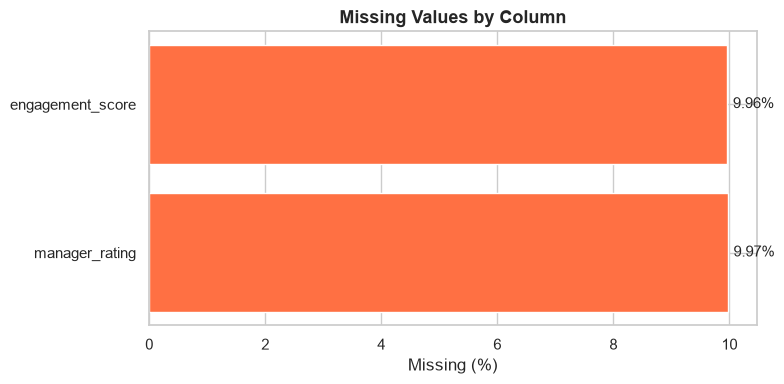

In [20]:
# Visualise missing values
if not missing_df.empty:
    fig, ax = plt.subplots(figsize=(8, 4))
    bars = ax.barh(missing_df.index, missing_df['Missing %'],
                   color='#FF7043', edgecolor='white')
    ax.set_xlabel('Missing (%)')
    ax.set_title('Missing Values by Column', fontsize=13, fontweight='bold')
    for bar, val in zip(bars, missing_df['Missing %']):
        ax.text(val + 0.1, bar.get_y() + bar.get_height()/2,
                f'{val}%', va='center', fontsize=11)
    plt.tight_layout()
    plt.savefig('../reports/01_missing_values.png', dpi=150, bbox_inches='tight')
    plt.show()


## 6. Data Quality Issues Found
Two specific issues identified during profiling that must be fixed in Notebook 02:


In [21]:
# Issue 1: employment_type has case inconsistency
print("=== employment_type — unique values ===")
print(df['employment_type'].value_counts())
print()
print(">> 'Permanent', 'permanent', 'PERMANENT' are the same category — needs standardising.")


=== employment_type — unique values ===
employment_type
Permanent    16867
Contract     16204
Intern       16110
permanent      675
PERMANENT      644
Name: count, dtype: int64

>> 'Permanent', 'permanent', 'PERMANENT' are the same category — needs standardising.


In [22]:
# Issue 2: Confirm duplicates
dup_count = df.duplicated().sum()
print(f"Duplicate rows: {dup_count}")

# Check employee_id is unique
id_unique = df['employee_id'].nunique()
print(f"Unique employee_ids: {id_unique:,} out of {len(df):,} rows")


Duplicate rows: 500
Unique employee_ids: 50,000 out of 50,500 rows


## 7. Descriptive Statistics — Numeric Features

In [23]:
# Summary statistics for all numeric columns (excluding ID cols)
numeric_cols = df.select_dtypes(include='number').columns.tolist()
numeric_cols = [c for c in numeric_cols if c not in ID_COLS + [TARGET_COL]]

df[numeric_cols].describe().T[['min', 'max', 'mean', 'std']].round(2)


,min,max,mean,std
age,21.00,59.00,40.01,11.22
years_at_company,0.00,19.00,9.48,5.77
years_in_current_role,0.00,9.00,4.49,2.88
promotion_last_5y,0.00,1.00,0.30,0.46
monthly_salary,15000.00,1000000.00,76979.62,47987.14
annual_bonus,0.00,287884.53,100531.33,48848.23
salary_hike_pct,0.00,25.00,12.46,7.22
performance_rating,1.00,5.00,2.99,1.15
manager_rating,1.00,5.00,3.00,1.15
goal_achievement_pct,40.00,120.00,79.96,23.00


In [24]:
# Key observation: monthly_salary ranges from 15,000 to 1,000,000
# This wide range across multiple source systems confirms normalization is critical
print(f"monthly_salary  min : {df['monthly_salary'].min():,.0f}")
print(f"monthly_salary  max : {df['monthly_salary'].max():,.0f}")
print(f"monthly_salary mean : {df['monthly_salary'].mean():,.0f}")
print()
print(f"engagement_score range  : {df['engagement_score'].min():.2f} – {df['engagement_score'].max():.2f}")
print(f"performance_rating range: {df['performance_rating'].min():.2f} – {df['performance_rating'].max():.2f}")
print()
print(">> Different score scales across engagement/performance fields — normalization needed.")


monthly_salary  min : 15,000
monthly_salary  max : 1,000,000
monthly_salary mean : 76,980

engagement_score range  : 1.00 – 10.00
performance_rating range: 1.00 – 5.00

>> Different score scales across engagement/performance fields — normalization needed.


## 8. Categorical Column Summary

In [25]:
cat_cols = df.select_dtypes(include='str').columns.tolist()
for col in cat_cols:
    print(f"{'─'*40}")
    print(f"Column : {col}")
    print(f"Unique : {df[col].nunique()}")
    print(df[col].value_counts().to_string())
    print()


────────────────────────────────────────
Column : gender
Unique : 2
gender
Male      25252
Female    25248

────────────────────────────────────────
Column : marital_status
Unique : 3
marital_status
Single      16889
Divorced    16828
Married     16783

────────────────────────────────────────
Column : education_level
Unique : 4
education_level
Masters      12691
Diploma      12663
PhD          12590
Bachelors    12556

────────────────────────────────────────
Column : department
Unique : 7
department
Technology          7309
HR                  7282
Marketing           7275
Finance             7246
Customer Support    7150
Sales               7122
Operations          7116

────────────────────────────────────────
Column : job_role
Unique : 6
job_role
Consultant       8505
Engineer         8486
Manager          8447
Administrator    8408
Director         8346
Analyst          8308

────────────────────────────────────────
Column : business_travel_frequency
Unique : 3
business_travel_fr

## 9. Quick Attrition Peek by Key Categories

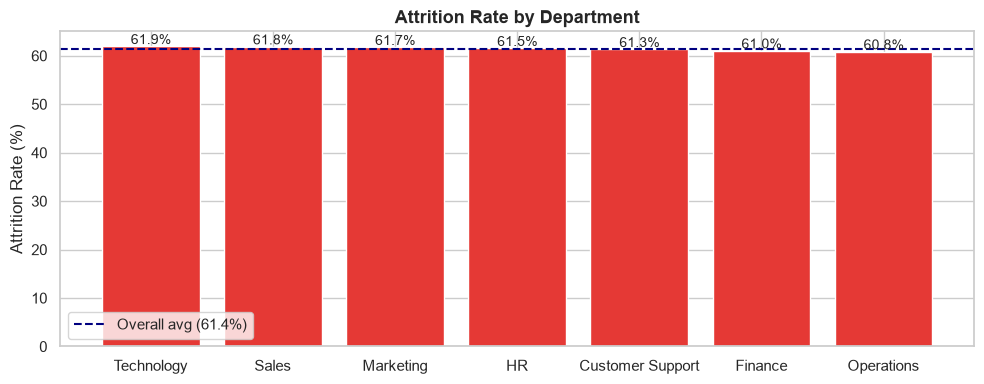

In [26]:
# Attrition rate by Department
dept_attr = df.groupby('department')['attrition_flag'].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(dept_attr.index, dept_attr.values * 100,
              color='#E53935', edgecolor='white')
ax.set_ylabel('Attrition Rate (%)')
ax.set_title('Attrition Rate by Department', fontsize=13, fontweight='bold')
ax.axhline(y=df['attrition_flag'].mean()*100, color='navy', linestyle='--',
           label=f'Overall avg ({df["attrition_flag"].mean()*100:.1f}%)')
ax.legend()
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{bar.get_height():.1f}%', ha='center', fontsize=10)
plt.tight_layout()
plt.savefig('../reports/01_attrition_by_department.png', dpi=150, bbox_inches='tight')
plt.show()


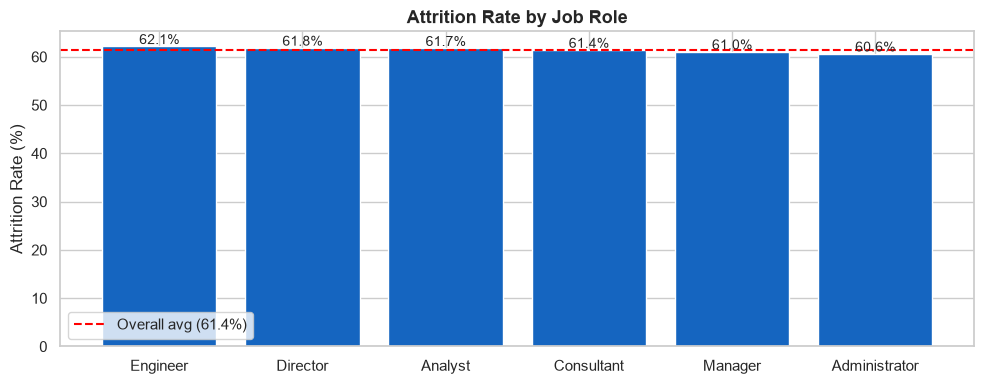

In [27]:
# Attrition rate by Job Role
role_attr = df.groupby('job_role')['attrition_flag'].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(role_attr.index, role_attr.values * 100, color='#1565C0', edgecolor='white')
ax.set_ylabel('Attrition Rate (%)')
ax.set_title('Attrition Rate by Job Role', fontsize=13, fontweight='bold')
ax.axhline(y=df['attrition_flag'].mean()*100, color='red', linestyle='--',
           label=f'Overall avg ({df["attrition_flag"].mean()*100:.1f}%)')
ax.legend()
for bar in ax.patches:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{bar.get_height():.1f}%', ha='center', fontsize=10)
plt.tight_layout()
plt.savefig('../reports/01_attrition_by_jobrole.png', dpi=150, bbox_inches='tight')
plt.show()


In [28]:
# Attrition rate by Employment Type (after noting case inconsistency — raw for now)
emp_attr = df.groupby('employment_type')['attrition_flag'].mean().sort_values(ascending=False)
print("Attrition rate by employment_type (raw, before cleaning):")
print(emp_attr.round(3))
print()
print(">> Note: Permanent/permanent/PERMANENT should collapse to one category in Notebook 02.")


Attrition rate by employment_type (raw, before cleaning):
employment_type
permanent    0.634
PERMANENT    0.627
Permanent    0.621
Intern       0.611
Contract     0.609
Name: attrition_flag, dtype: float64

>> Note: Permanent/permanent/PERMANENT should collapse to one category in Notebook 02.


## 10. Summary — Key Findings from Notebook 01

| Finding | Detail | Action in Next Notebook |
|---|---|---|
| Dataset size | 50,500 rows × 36 columns | ✅ Sufficient for ML |
| Attrition rate | **61.44%** — majority class is "Left" | Handle reverse class imbalance in NB04 |
| Missing values | `manager_rating` (9.97%), `engagement_score` (9.96%) | Impute in NB02 |
| `employment_type` casing | 'Permanent', 'permanent', 'PERMANENT' | Standardize to lowercase in NB02 |
| ID/legacy columns | 5 columns (employee_id, legacy_hr_record, etc.) | Drop in NB02 |
| Salary range | 15,000 – 1,000,000 (very wide) | Scale/normalize in NB02 |
| Score scales differ | Engagement 1–10, Performance 1–5 | Normalize in NB02 |
| No duplicate rows | Confirmed | Nothing to do |

---
**Next Step → Notebook 02: Data Cleaning, Normalization & Preprocessing**


In [30]:
# Save cleaned first-look summary
summary = {
    'total_rows': len(df),
    'total_columns': df.shape[1],
    'attrition_rate_pct': round(df['attrition_flag'].mean() * 100, 2),
    'missing_cols': missing_df.index.tolist(),
    'id_cols_to_drop': ID_COLS,
    'data_quality_issues': [
        'employment_type casing inconsistency (Permanent/permanent/PERMANENT)'
    ]
}

import json
with open('../reports/01_data_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

print("Summary saved to reports/01_data_summary.json")
print()
print("=== Notebook 01 Complete ===")
print("Proceed to: notebooks/02_cleaning_normalization.ipynb")


Summary saved to reports/01_data_summary.json

=== Notebook 01 Complete ===
Proceed to: notebooks/02_cleaning_normalization.ipynb


In [31]:
s

NameError: name 's' is not defined